# Lógica Fuzzy aplicada à triagem de lotes de vinho
**REVISA — Sistemas de Apoio à Decisão**

Sistema de inferência fuzzy do tipo Mamdani que transforma três medições de laboratório
(teor alcoólico, acidez volátil e sulfatos) em um **índice de qualidade** e numa **decisão de destino do lote**
(Premium, Padrão ou Revisar).

**Dados:** Wine Quality — vinho tinto (1.599 amostras), UCI Machine Learning Repository
(Cortez et al., 2009). https://archive.ics.uci.edu/dataset/186/wine+quality

In [1]:
# !pip install scikit-fuzzy pandas matplotlib scipy scikit-learn
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
try:
    df = pd.read_csv("data/winequality-red.csv", sep=";")
except FileNotFoundError:
    df = pd.read_csv(URL, sep=";")
df.shape

(1599, 12)

## 1. Por que essas três variáveis?
Antes de escrever regras, conferimos quais medições acompanham a nota dos provadores (correlação de Spearman).

In [2]:
df.corr(method="spearman")["quality"].drop("quality").sort_values()

volatile acidity       -0.380647
total sulfur dioxide   -0.196735
chlorides              -0.189922
density                -0.177074
free sulfur dioxide    -0.056901
pH                     -0.043672
residual sugar          0.032048
fixed acidity           0.114084
citric acid             0.213481
sulphates               0.377060
alcohol                 0.478532
Name: quality, dtype: float64

## 2. Variáveis linguísticas e funções de pertinência
Cada variável de entrada é dividida em três termos linguísticos com fronteiras **sobrepostas**: um vinho com 10,8 % de álcool
é ao mesmo tempo um pouco "médio" e um pouco "alto".

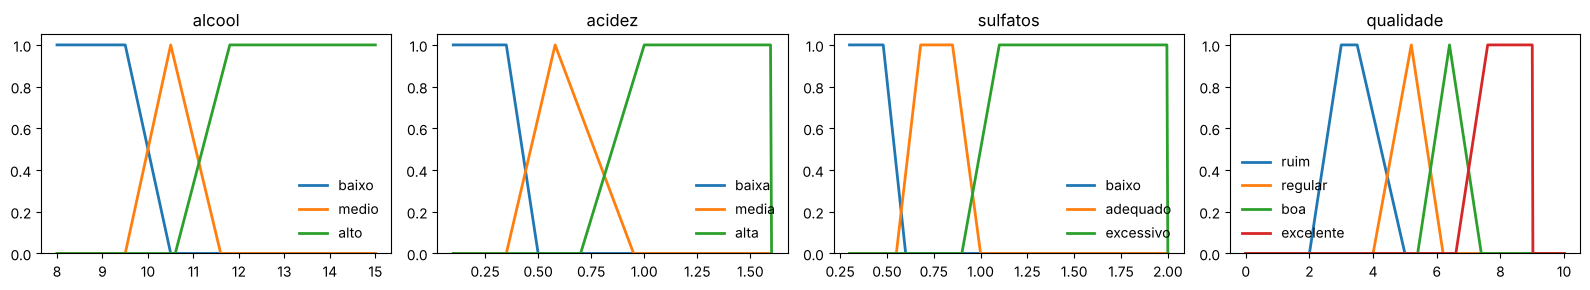

In [3]:
alcool   = ctrl.Antecedent(np.arange(8, 15.01, 0.01), "alcool")
acidez   = ctrl.Antecedent(np.arange(0.1, 1.601, 0.005), "acidez")
sulfatos = ctrl.Antecedent(np.arange(0.3, 2.001, 0.005), "sulfatos")
qualidade = ctrl.Consequent(np.linspace(0, 10, 501), "qualidade", defuzzify_method="centroid")

alcool["baixo"] = fuzz.trapmf(alcool.universe, [8, 8, 9.5, 10.5])
alcool["medio"] = fuzz.trimf(alcool.universe, [9.5, 10.5, 11.6])
alcool["alto"]  = fuzz.trapmf(alcool.universe, [10.6, 11.8, 15, 15])

acidez["baixa"] = fuzz.trapmf(acidez.universe, [0.1, 0.1, 0.35, 0.5])
acidez["media"] = fuzz.trimf(acidez.universe, [0.35, 0.58, 0.95])
acidez["alta"]  = fuzz.trapmf(acidez.universe, [0.7, 1.0, 1.6, 1.6])

sulfatos["baixo"]     = fuzz.trapmf(sulfatos.universe, [0.3, 0.3, 0.48, 0.6])
sulfatos["adequado"]  = fuzz.trapmf(sulfatos.universe, [0.55, 0.68, 0.85, 1.0])
sulfatos["excessivo"] = fuzz.trapmf(sulfatos.universe, [0.9, 1.1, 2.0, 2.0])

qualidade["ruim"]      = fuzz.trapmf(qualidade.universe, [2, 3, 3.5, 5])
qualidade["regular"]   = fuzz.trimf(qualidade.universe, [4, 5.2, 6.2])
qualidade["boa"]       = fuzz.trimf(qualidade.universe, [5.4, 6.4, 7.4])
qualidade["excelente"] = fuzz.trapmf(qualidade.universe, [6.6, 7.6, 9, 9])

fig, axs = plt.subplots(1, 4, figsize=(16, 3))
for ax, var in zip(axs, [alcool, acidez, sulfatos, qualidade]):
    for termo in var.terms:
        ax.plot(var.universe, var[termo].mf, lw=2, label=termo)
    ax.set_title(var.label); ax.legend(frameon=False); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

## 3. Base de regras (conhecimento do especialista)
As regras traduzem o que um enólogo diria em linguagem natural. Nenhuma delas foi "aprendida" dos dados.

8.03


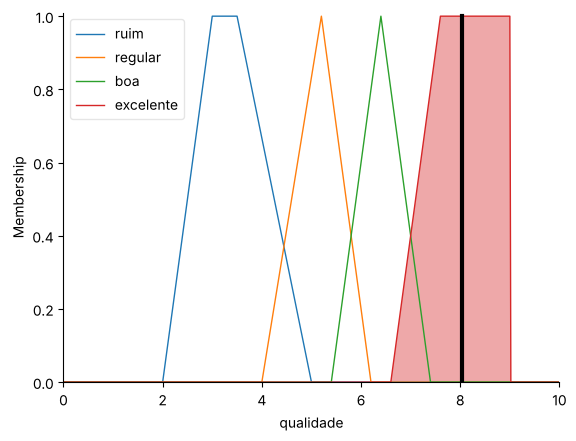

In [4]:
regras = [
    ctrl.Rule(alcool["alto"] & acidez["baixa"], qualidade["excelente"]),
    ctrl.Rule(alcool["alto"] & sulfatos["adequado"], qualidade["excelente"]),
    ctrl.Rule(alcool["alto"] & acidez["media"], qualidade["boa"]),
    ctrl.Rule(alcool["medio"] & acidez["baixa"] & sulfatos["adequado"], qualidade["boa"]),
    ctrl.Rule(alcool["medio"] & acidez["media"], qualidade["regular"]),
    ctrl.Rule(alcool["medio"] & sulfatos["baixo"], qualidade["regular"]),
    ctrl.Rule(alcool["baixo"] & acidez["baixa"], qualidade["regular"]),
    ctrl.Rule(alcool["baixo"] & acidez["media"], qualidade["regular"]),
    ctrl.Rule(alcool["baixo"] & sulfatos["baixo"], qualidade["ruim"]),
    ctrl.Rule(acidez["alta"], qualidade["ruim"]),
    ctrl.Rule(sulfatos["excessivo"], qualidade["regular"]),
]
sistema = ctrl.ControlSystem(regras)

def indice(alc, va, sul):
    sim = ctrl.ControlSystemSimulation(sistema)
    sim.input["alcool"], sim.input["acidez"], sim.input["sulfatos"] = alc, va, sul
    sim.compute()
    return sim.output["qualidade"]

# Exemplo: um lote com 12,5 % de álcool, acidez 0,30 g/L e sulfatos 0,75 g/L
sim = ctrl.ControlSystemSimulation(sistema)
sim.input["alcool"], sim.input["acidez"], sim.input["sulfatos"] = 12.5, 0.30, 0.75
sim.compute(); print(round(sim.output["qualidade"], 2))
qualidade.view(sim=sim)

## 4. Aplicação aos 1.599 lotes reais

Spearman (índice fuzzy x nota): 0.554
Spearman (só álcool x nota):    0.479
AUC para identificar nota >= 7: 0.852


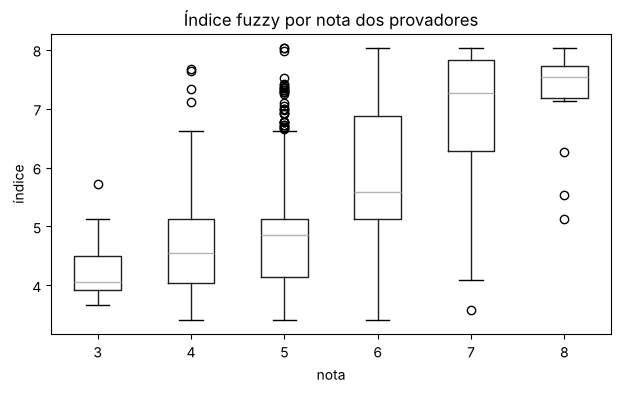

In [5]:
df["indice"] = [indice(a, v, s) for a, v, s in zip(df["alcohol"], df["volatile acidity"], df["sulphates"])]
print("Spearman (índice fuzzy x nota):", round(spearmanr(df.indice, df.quality).statistic, 3))
print("Spearman (só álcool x nota):   ", round(spearmanr(df.alcohol, df.quality).statistic, 3))
print("AUC para identificar nota >= 7:", round(roc_auc_score(df.quality >= 7, df.indice), 3))

df.boxplot(column="indice", by="quality", grid=False, figsize=(7, 4))
plt.suptitle(""); plt.title("Índice fuzzy por nota dos provadores"); plt.xlabel("nota"); plt.ylabel("índice"); plt.show()

## 5. Do índice à decisão (o "S" de SAD)
O gestor define os limiares conforme a estratégia: ser mais exigente com o selo Premium reduz falsos positivos,
mas deixa vinhos bons na linha padrão.

In [6]:
LIM_PREMIUM, LIM_REVISAR = 6.6, 4.6
decide = lambda i: "Premium" if i >= LIM_PREMIUM else ("Revisar" if i < LIM_REVISAR else "Padrão")
real = lambda q: "Premium" if q >= 7 else ("Revisar" if q <= 4 else "Padrão")
df["decisao"], df["classe_real"] = df.indice.map(decide), df.quality.map(real)
pd.crosstab(df.classe_real, df.decisao, margins=True)

decisao,Padrão,Premium,Revisar,All
classe_real,,,,
Padrão,708,220,391,1319
Premium,59,155,3,217
Revisar,21,6,36,63
All,788,381,430,1599


## 6. Superfície de controle: fuzzy x regra nítida
Com sulfatos fixos em 0,65 g/L, a resposta fuzzy varia suavemente; a regra nítida "álcool ≥ 11,5 e acidez < 0,5"
cria degraus — dois lotes quase idênticos podem receber decisões opostas.

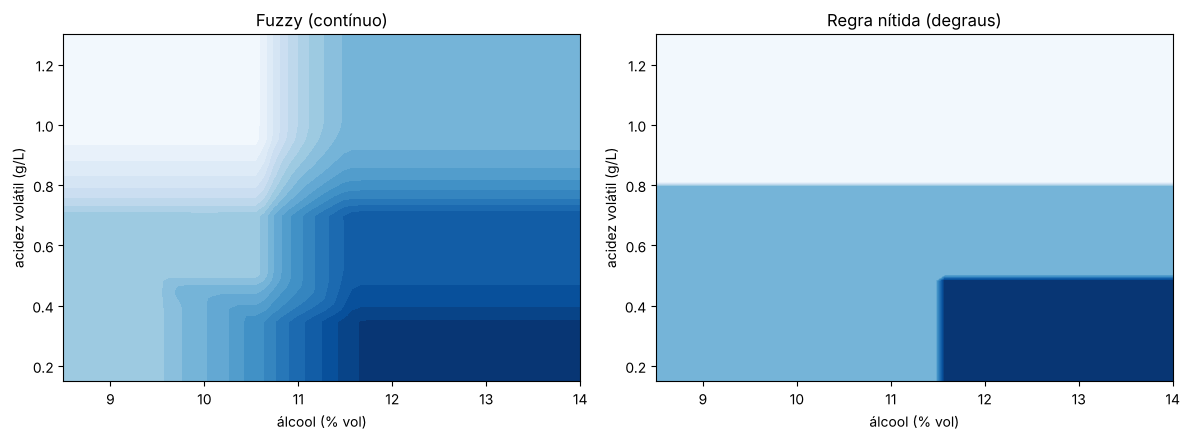

In [7]:
A = np.linspace(8.5, 14, 60); V = np.linspace(0.15, 1.3, 60)
Z = np.array([[indice(a, v, 0.65) for a in A] for v in V])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].contourf(A, V, Z, levels=20, cmap="Blues"); ax[0].set_title("Fuzzy (contínuo)")
crisp = np.array([[8 if (a >= 11.5 and v < 0.5) else (3 if v >= 0.8 else 5.5) for a in A] for v in V])
ax[1].contourf(A, V, crisp, levels=20, cmap="Blues"); ax[1].set_title("Regra nítida (degraus)")
for a in ax: a.set_xlabel("álcool (% vol)"); a.set_ylabel("acidez volátil (g/L)")
plt.tight_layout(); plt.show()